<a href="https://colab.research.google.com/github/Vijayragav-V/SlickNet/blob/main/notebooks/SlickNetv1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print(device)

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

cuda
Tesla T4


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path

PROJECT_DRIVE = Path(
    "/content/drive/MyDrive/SlickNet"
)

PROJECT_DRIVE.mkdir(
    parents=True,
    exist_ok=True
)

(PROJECT_DRIVE / "models").mkdir(
    exist_ok=True
)

In [ ]:
!apt-get -qq update
!apt-get -qq install git-lfs
!git lfs install

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Updated Git hooks.
Git LFS initialized.


In [ ]:
!git clone https://github.com/Garcia-INPE/oilspill-detection-dataset.git /content/oilspill-data

fatal: destination path '/content/oilspill-data' already exists and is not an empty directory.


In [ ]:
%cd /content/oilspill-data
!git lfs pull

/content/oilspill-data


In [ ]:
from pathlib import Path

DATA_ROOT = Path("/content/oilspill-data")

print(list((DATA_ROOT / "splits").iterdir()))

[PosixPath('/content/oilspill-data/splits/val.csv'), PosixPath('/content/oilspill-data/splits/test.csv'), PosixPath('/content/oilspill-data/splits/train.csv')]


In [ ]:
import pandas as pd

train_df = pd.read_csv(
    DATA_ROOT / "splits/train.csv"
)

val_df = pd.read_csv(
    DATA_ROOT / "splits/val.csv"
)

test_df = pd.read_csv(
    DATA_ROOT / "splits/test.csv"
)

display(train_df.head())

print(len(train_df))
print(len(val_df))
print(len(test_df))

,sample_id,image_path,mask_path,classe,subclasse
0,IMG_01_TILE_001,IMAGES/IMG-RGB/IMG_01_TILE_001.png,IMAGES/LABELS-1D/IMG_01_TILE_001_1D.png,NaN,NaN
1,IMG_01_TILE_002,IMAGES/IMG-RGB/IMG_01_TILE_002.png,IMAGES/LABELS-1D/IMG_01_TILE_002_1D.png,NaN,NaN
2,IMG_02_TILE_001,IMAGES/IMG-RGB/IMG_02_TILE_001.png,IMAGES/LABELS-1D/IMG_02_TILE_001_1D.png,NaN,NaN
3,IMG_02_TILE_002,IMAGES/IMG-RGB/IMG_02_TILE_002.png,IMAGES/LABELS-1D/IMG_02_TILE_002_1D.png,NaN,NaN
4,IMG_02_TILE_003,IMAGES/IMG-RGB/IMG_02_TILE_003.png,IMAGES/LABELS-1D/IMG_02_TILE_003_1D.png,NaN,NaN


108
43
22


In [ ]:
print(train_df.columns)

Index(['sample_id', 'image_path', 'mask_path', 'classe', 'subclasse'], dtype='object')


In [ ]:
from PIL import Image

row = train_df.iloc[0]

image = Image.open(
    DATA_ROOT / row["image_path"]
)

mask = Image.open(
    DATA_ROOT / row["mask_path"]
)

print(image.size)
print(mask.size)
print(image.mode)
print(mask.mode)

(800, 600)
(800, 600)
RGB
L


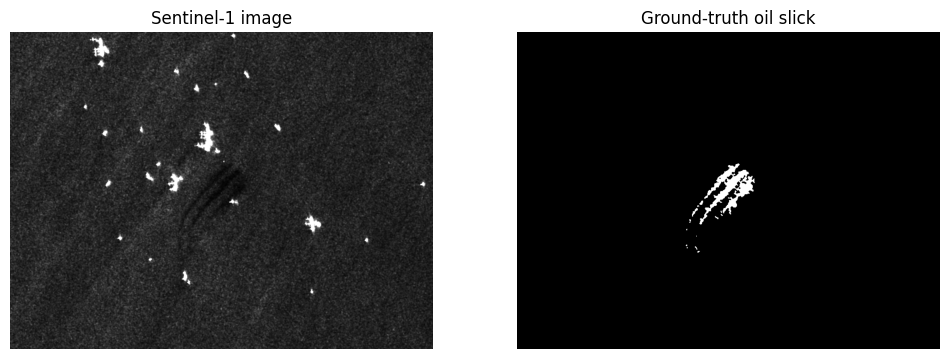

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Sentinel-1 image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap="gray")
plt.title("Ground-truth oil slick")
plt.axis("off")

plt.show()

In [ ]:
import random
import numpy as np

import torch

from torch.utils.data import Dataset
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode

In [ ]:
class OilSpillDataset(Dataset):

    def __init__(
        self,
        dataframe,
        root,
        augment=False,
        size=(288, 384)
    ):
        self.df = dataframe.reset_index(drop=True)
        self.root = Path(root)
        self.augment = augment
        self.size = size


    def __len__(self):
        return len(self.df)


    def __getitem__(self, index):

        row = self.df.iloc[index]

        image = Image.open(
            self.root / row["image_path"]
        ).convert("RGB")

        mask = Image.open(
            self.root / row["mask_path"]
        ).convert("L")


        # Same random transformation must
        # happen to image AND mask.

        if self.augment:

            if random.random() < 0.5:
                image = TF.hflip(image)
                mask = TF.hflip(mask)

            if random.random() < 0.5:
                image = TF.vflip(image)
                mask = TF.vflip(mask)


        image = TF.resize(
            image,
            self.size,
            interpolation=InterpolationMode.BILINEAR
        )

        mask = TF.resize(
            mask,
            self.size,
            interpolation=InterpolationMode.NEAREST
        )


        # image:
        # [H,W,RGB] → [3,H,W]
        # values become 0..1

        image = TF.to_tensor(image)


        mask = np.array(mask)

        # Dataset masks use:
        # 0 = ocean
        # >0 = slick

        mask = (
            mask > 0
        ).astype(np.float32)

        mask = torch.from_numpy(
            mask
        ).unsqueeze(0)


        return image, mask

In [ ]:
train_dataset = OilSpillDataset(
    train_df,
    DATA_ROOT,
    augment=True
)

image_tensor, mask_tensor = (
    train_dataset[0]
)

print(image_tensor.shape)
print(mask_tensor.shape)

print(
    mask_tensor.unique()
)

torch.Size([3, 288, 384])
torch.Size([1, 288, 384])
tensor([0., 1.])


In [ ]:
from torch.utils.data import DataLoader

In [ ]:
val_dataset = OilSpillDataset(
    val_df,
    DATA_ROOT,
    augment=False
)

test_dataset = OilSpillDataset(
    test_df,
    DATA_ROOT,
    augment=False
)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

In [ ]:
import torch.nn as nn

In [ ]:
class DoubleConv(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels
    ):
        super().__init__()

        self.block = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(
                out_channels
            ),

            nn.ReLU(inplace=True)
        )


    def forward(self, x):
        return self.block(x)

In [ ]:
class UNet(nn.Module):

    def __init__(
        self,
        in_channels=3,
        out_channels=1
    ):
        super().__init__()


        self.enc1 = DoubleConv(
            in_channels, 16
        )

        self.enc2 = DoubleConv(
            16, 32
        )

        self.enc3 = DoubleConv(
            32, 64
        )

        self.enc4 = DoubleConv(
            64, 128
        )


        self.pool = nn.MaxPool2d(
            2
        )


        self.bottleneck = DoubleConv(
            128, 256
        )


        self.up4 = nn.ConvTranspose2d(
            256,
            128,
            kernel_size=2,
            stride=2
        )

        self.dec4 = DoubleConv(
            256,
            128
        )


        self.up3 = nn.ConvTranspose2d(
            128,
            64,
            kernel_size=2,
            stride=2
        )

        self.dec3 = DoubleConv(
            128,
            64
        )


        self.up2 = nn.ConvTranspose2d(
            64,
            32,
            kernel_size=2,
            stride=2
        )

        self.dec2 = DoubleConv(
            64,
            32
        )


        self.up1 = nn.ConvTranspose2d(
            32,
            16,
            kernel_size=2,
            stride=2
        )

        self.dec1 = DoubleConv(
            32,
            16
        )


        self.output = nn.Conv2d(
            16,
            out_channels,
            kernel_size=1
        )


    def forward(self, x):

        e1 = self.enc1(x)

        e2 = self.enc2(
            self.pool(e1)
        )

        e3 = self.enc3(
            self.pool(e2)
        )

        e4 = self.enc4(
            self.pool(e3)
        )


        b = self.bottleneck(
            self.pool(e4)
        )


        d4 = self.up4(b)

        d4 = torch.cat(
            [d4, e4],
            dim=1
        )

        d4 = self.dec4(d4)


        d3 = self.up3(d4)

        d3 = torch.cat(
            [d3, e3],
            dim=1
        )

        d3 = self.dec3(d3)


        d2 = self.up2(d3)

        d2 = torch.cat(
            [d2, e2],
            dim=1
        )

        d2 = self.dec2(d2)


        d1 = self.up1(d2)

        d1 = torch.cat(
            [d1, e1],
            dim=1
        )

        d1 = self.dec1(d1)


        return self.output(d1)

In [ ]:
model = UNet().to(device)

In [ ]:
images, masks = next(
    iter(train_loader)
)

images = images.to(device)

outputs = model(images)

print(images.shape)
print(outputs.shape)

torch.Size([8, 3, 288, 384])
torch.Size([8, 1, 288, 384])


In [ ]:
probabilities = torch.sigmoid(
    outputs
)

mask = probabilities > 0.5

In [ ]:
# Binary Cross Entropy loss
bce_loss = nn.BCEWithLogitsLoss()


def dice_loss(logits, targets, smooth=1.0):
    """
    Measures how much the predicted oil region overlaps
    with the actual oil region.
    """

    # Convert raw model outputs (logits) into probabilities
    probs = torch.sigmoid(logits)

    # Flatten each image/mask into one long vector
    probs = probs.view(probs.size(0), -1)
    targets = targets.view(targets.size(0), -1)

    # Pixels where prediction and ground truth overlap
    intersection = (probs * targets).sum(dim=1)

    # Dice coefficient
    dice = (
        2 * intersection + smooth
    ) / (
        probs.sum(dim=1)
        + targets.sum(dim=1)
        + smooth
    )

    # Loss needs to decrease, so convert:
    # perfect Dice = 1 -> loss = 0
    return 1 - dice.mean()


def combined_loss(logits, targets):
    """
    Combines pixel-level BCE loss with region-overlap Dice loss.
    """

    bce = bce_loss(logits, targets)
    dice = dice_loss(logits, targets)

    return 0.5 * bce + 0.5 * dice

In [ ]:
def calculate_iou(
    logits,
    targets,
    threshold=0.5
):

    probs = torch.sigmoid(
        logits
    )

    preds = (
        probs > threshold
    ).float()


    intersection = (
        preds * targets
    ).sum(
        dim=(1, 2, 3)
    )


    union = (
        preds
        +
        targets
        -
        preds * targets
    ).sum(
        dim=(1, 2, 3)
    )


    iou = (
        intersection + 1e-6
    ) / (
        union + 1e-6
    )


    return iou.mean().item()

In [ ]:
tiny_loader = DataLoader(
    torch.utils.data.Subset(
        train_dataset,
        [0]
    ),
    batch_size=1,
    shuffle=True
)

In [ ]:
model = UNet().to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

In [ ]:
def train_one_epoch(
    model,
    loader,
    optimizer,
    device
):

    model.train()

    total_loss = 0
    total_iou = 0


    for images, masks in loader:

        images = images.to(
            device
        )

        masks = masks.to(
            device
        )


        optimizer.zero_grad()


        logits = model(
            images
        )


        loss = combined_loss(
            logits,
            masks
        )


        loss.backward()

        optimizer.step()


        total_loss += (
            loss.item()
        )

        total_iou += calculate_iou(
            logits.detach(),
            masks
        )


    return (
        total_loss / len(loader),
        total_iou / len(loader)
    )

In [ ]:
def validate(
    model,
    loader,
    device
):

    model.eval()

    total_loss = 0
    total_iou = 0


    with torch.no_grad():

        for images, masks in loader:

            images = images.to(
                device
            )

            masks = masks.to(
                device
            )


            logits = model(
                images
            )


            loss = combined_loss(
                logits,
                masks
            )


            total_loss += (
                loss.item()
            )

            total_iou += (
                calculate_iou(
                    logits,
                    masks
                )
            )


    return (
        total_loss / len(loader),
        total_iou / len(loader)
    )

In [ ]:
history = {
    "train_loss": [],
    "val_loss": [],
    "train_iou": [],
    "val_iou": []
}

EPOCHS = 30

best_iou = -1

MODEL_PATH = (
    PROJECT_DRIVE
    / "models"
    / "slicknet_v1.pth"
)


for epoch in range(EPOCHS):

    train_loss, train_iou = (
        train_one_epoch(
            model,
            train_loader,
            optimizer,
            device
        )
    )


    val_loss, val_iou = (
        validate(
            model,
            val_loader,
            device
        )
    )


    print(
        f"Epoch {epoch+1:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train IoU: {train_iou:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val IoU: {val_iou:.4f}"
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_iou"].append(train_iou)
    history["val_iou"].append(val_iou)


    if val_iou > best_iou:

        best_iou = val_iou

        torch.save(
            model.state_dict(),
            MODEL_PATH
        )

        print(
            "Saved new best model."
        )

Epoch 01 | Train Loss: 0.6988 | Train IoU: 0.2431 | Val Loss: 0.7313 | Val IoU: 0.0000
Saved new best model.
Epoch 02 | Train Loss: 0.6347 | Train IoU: 0.4191 | Val Loss: 0.6432 | Val IoU: 0.0248
Saved new best model.
Epoch 03 | Train Loss: 0.6054 | Train IoU: 0.4234 | Val Loss: 0.6178 | Val IoU: 0.0158
Epoch 04 | Train Loss: 0.5858 | Train IoU: 0.4247 | Val Loss: 0.5658 | Val IoU: 0.3814
Saved new best model.
Epoch 05 | Train Loss: 0.5662 | Train IoU: 0.4464 | Val Loss: 0.5640 | Val IoU: 0.4146
Saved new best model.
Epoch 06 | Train Loss: 0.5511 | Train IoU: 0.4352 | Val Loss: 0.5531 | Val IoU: 0.3768
Epoch 07 | Train Loss: 0.5358 | Train IoU: 0.4356 | Val Loss: 0.5561 | Val IoU: 0.3139
Epoch 08 | Train Loss: 0.5158 | Train IoU: 0.4684 | Val Loss: 0.5171 | Val IoU: 0.4773
Saved new best model.
Epoch 09 | Train Loss: 0.5027 | Train IoU: 0.4538 | Val Loss: 0.4902 | Val IoU: 0.5203
Saved new best model.
Epoch 10 | Train Loss: 0.4823 | Train IoU: 0.4919 | Val Loss: 0.4828 | Val IoU: 0.406

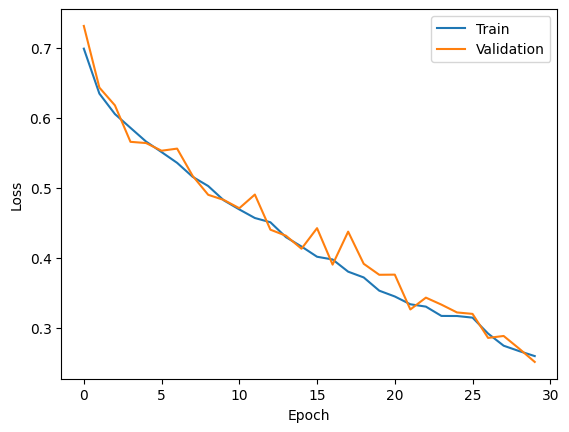

In [ ]:
plt.plot(
    history["train_loss"],
    label="Train"
)

plt.plot(
    history["val_loss"],
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

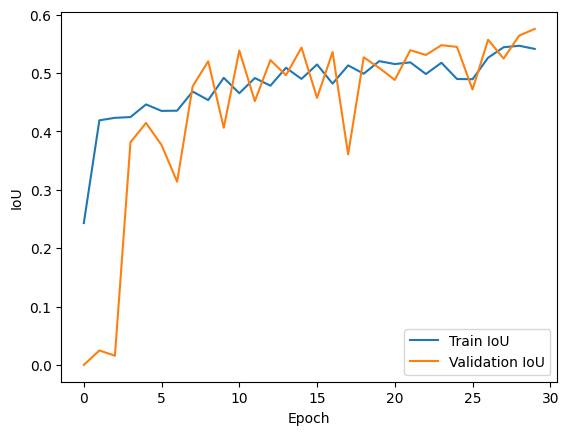

In [ ]:
plt.plot(
    history["train_iou"],
    label="Train IoU"
)

plt.plot(
    history["val_iou"],
    label="Validation IoU"
)

plt.xlabel("Epoch")
plt.ylabel("IoU")
plt.legend()
plt.show()

In [ ]:
model.load_state_dict(
    torch.load(
        MODEL_PATH,
        map_location=device
    )
)

<All keys matched successfully>

In [ ]:
test_loss, test_iou = validate(
    model,
    test_loader,
    device
)

print(
    "Test IoU:",
    test_iou
)

Test IoU: 0.5259249210357666


In [ ]:
model.eval()

images, masks = next(
    iter(test_loader)
)

with torch.no_grad():

    logits = model(
        images.to(device)
    )

    probabilities = torch.sigmoid(
        logits
    )

    predictions = (
        probabilities > 0.5
    ).float().cpu()

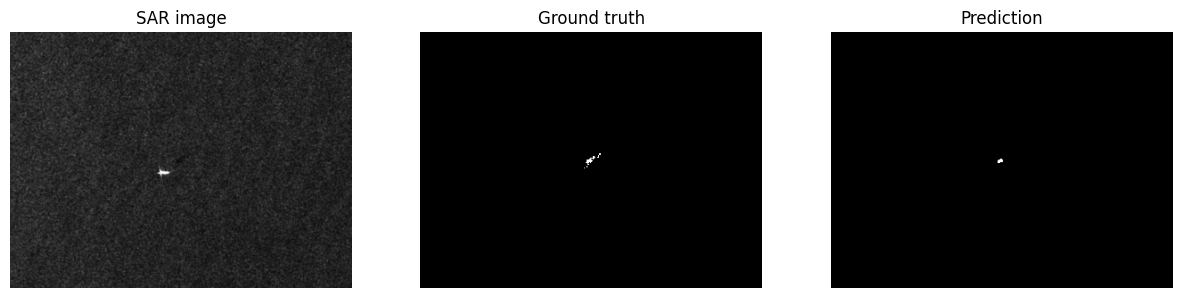

In [ ]:
index = 0

plt.figure(
    figsize=(15, 5)
)

plt.subplot(1, 3, 1)
plt.imshow(
    images[index]
    .permute(1, 2, 0)
)
plt.title("SAR image")
plt.axis("off")


plt.subplot(1, 3, 2)
plt.imshow(
    masks[index, 0],
    cmap="gray"
)
plt.title("Ground truth")
plt.axis("off")


plt.subplot(1, 3, 3)
plt.imshow(
    predictions[index, 0],
    cmap="gray"
)
plt.title("Prediction")
plt.axis("off")

plt.show()

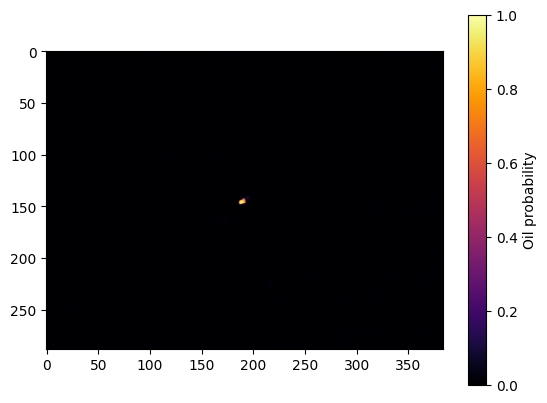

In [ ]:
prob = (
    probabilities[index, 0]
    .cpu()
    .numpy()
)

plt.imshow(
    prob,
    cmap="inferno",
    vmin=0,
    vmax=1
)

plt.colorbar(
    label="Oil probability"
)

plt.show()

In [ ]:
predicted_mask = (
    predictions[index, 0]
    .numpy()
    .astype(np.uint8)
)

oil_pixels = predicted_mask.sum()

total_pixels = (
    predicted_mask.size
)

coverage = (
    oil_pixels
    / total_pixels
)

print(
    f"Image coverage: "
    f"{coverage:.2%}"
)

Image coverage: 0.02%


In [ ]:
import cv2
import numpy as np

num_labels, labels, stats, centroids = (
    cv2.connectedComponentsWithStats(
        predicted_mask.astype(np.uint8),
        connectivity=8
    )
)

In [ ]:
MIN_PIXELS = 100

valid_components = []

for label_id in range(
    1,
    num_labels
):

    area = stats[
        label_id,
        cv2.CC_STAT_AREA
    ]

    if area >= MIN_PIXELS:

        valid_components.append(
            label_id
        )

In [ ]:
model.load_state_dict(
    torch.load(
        MODEL_PATH,
        map_location=device
    )
)

model = model.to(device)
model.eval()

print("Best model loaded.")

Best model loaded.


In [ ]:
import numpy as np
import torch
import cv2


def remove_small_components(
    binary_mask,
    min_pixels=0
):
    """
    Removes connected predicted regions smaller
    than min_pixels.

    binary_mask must contain 0s and 1s.
    """

    if min_pixels <= 0:
        return binary_mask.astype(np.uint8)

    num_labels, labels, stats, _ = (
        cv2.connectedComponentsWithStats(
            binary_mask.astype(np.uint8),
            connectivity=8
        )
    )

    cleaned = np.zeros_like(
        binary_mask,
        dtype=np.uint8
    )

    for label_id in range(1, num_labels):

        area = stats[
            label_id,
            cv2.CC_STAT_AREA
        ]

        if area >= min_pixels:

            cleaned[
                labels == label_id
            ] = 1

    return cleaned

In [ ]:
@torch.no_grad()
def collect_predictions(
    model,
    loader,
    device
):
    model.eval()

    all_probs = []
    all_targets = []

    for images, masks in loader:

        images = images.to(device)

        logits = model(images)

        probs = torch.sigmoid(
            logits
        )

        all_probs.append(
            probs.cpu()
        )

        all_targets.append(
            masks.cpu()
        )

    all_probs = torch.cat(
        all_probs,
        dim=0
    )

    all_targets = torch.cat(
        all_targets,
        dim=0
    )

    return all_probs, all_targets

In [ ]:
val_probs, val_targets = (
    collect_predictions(
        model,
        val_loader,
        device
    )
)

print(
    "Validation probabilities:",
    val_probs.shape
)

print(
    "Validation targets:",
    val_targets.shape
)

Validation probabilities: torch.Size([43, 1, 288, 384])
Validation targets: torch.Size([43, 1, 288, 384])


In [ ]:
def evaluate_predictions(
    probabilities,
    targets,
    threshold=0.5,
    min_pixels=0
):

    total_tp = 0
    total_fp = 0
    total_fn = 0
    total_tn = 0

    image_ious = []
    image_dice = []

    for i in range(
        probabilities.shape[0]
    ):

        prob = (
            probabilities[i, 0]
            .numpy()
        )

        gt = (
            targets[i, 0]
            .numpy()
            >= 0.5
        ).astype(np.uint8)

        pred = (
            prob >= threshold
        ).astype(np.uint8)

        pred = remove_small_components(
            pred,
            min_pixels
        )

        tp = np.logical_and(
            pred == 1,
            gt == 1
        ).sum()

        fp = np.logical_and(
            pred == 1,
            gt == 0
        ).sum()

        fn = np.logical_and(
            pred == 0,
            gt == 1
        ).sum()

        tn = np.logical_and(
            pred == 0,
            gt == 0
        ).sum()

        total_tp += tp
        total_fp += fp
        total_fn += fn
        total_tn += tn

        union = tp + fp + fn

        if union == 0:
            image_iou = 1.0
        else:
            image_iou = (
                tp / union
            )

        dice_denominator = (
            2 * tp
            + fp
            + fn
        )

        if dice_denominator == 0:
            dice = 1.0
        else:
            dice = (
                2 * tp
                / dice_denominator
            )

        image_ious.append(
            image_iou
        )

        image_dice.append(
            dice
        )

    eps = 1e-8

    global_iou = (
        total_tp
        / (
            total_tp
            + total_fp
            + total_fn
            + eps
        )
    )

    global_dice = (
        2 * total_tp
        / (
            2 * total_tp
            + total_fp
            + total_fn
            + eps
        )
    )

    precision = (
        total_tp
        / (
            total_tp
            + total_fp
            + eps
        )
    )

    recall = (
        total_tp
        / (
            total_tp
            + total_fn
            + eps
        )
    )

    return {
        "global_iou": float(
            global_iou
        ),

        "global_dice": float(
            global_dice
        ),

        "precision": float(
            precision
        ),

        "recall": float(
            recall
        ),

        "mean_image_iou": float(
            np.mean(image_ious)
        ),

        "mean_image_dice": float(
            np.mean(image_dice)
        ),

        "tp": int(total_tp),
        "fp": int(total_fp),
        "fn": int(total_fn),
        "tn": int(total_tn)
    }

In [ ]:
baseline_metrics = (
    evaluate_predictions(
        val_probs,
        val_targets,
        threshold=0.5,
        min_pixels=100
    )
)

baseline_metrics

{'global_iou': 0.6437495166517401,
 'global_dice': 0.783269604194969,
 'precision': 0.8525922753174371,
 'recall': 0.7243722608103473,
 'mean_image_iou': 0.4734035295890528,
 'mean_image_dice': 0.5871734954707882,
 'tp': 91565,
 'fp': 15831,
 'fn': 34841,
 'tn': 4613219}

In [ ]:
import pandas as pd

thresholds = np.round(
    np.arange(
        0.20,
        0.81,
        0.05
    ),
    2
)

min_pixel_options = [
    0,
    25,
    50,
    100,
    200
]

results = []


for threshold in thresholds:

    for min_pixels in min_pixel_options:

        metrics = evaluate_predictions(
            val_probs,
            val_targets,
            threshold=threshold,
            min_pixels=min_pixels
        )

        results.append({
            "threshold": threshold,
            "min_pixels": min_pixels,
            **metrics
        })


tuning_df = pd.DataFrame(
    results
)

tuning_df = tuning_df.sort_values(
    "global_iou",
    ascending=False
)

tuning_df.head(15)

,threshold,min_pixels,global_iou,global_dice,precision,recall,mean_image_iou,mean_image_dice,tp,fp,fn,tn
31,0.50,25,0.659294,0.794668,0.838624,0.755091,0.558846,0.692897,95448,18367,30958,4610683
26,0.45,25,0.658919,0.794396,0.828736,0.762788,0.556529,0.691322,96421,19926,29985,4609124
21,0.40,25,0.658339,0.793974,0.818904,0.770517,0.554194,0.689391,97398,21539,29008,4607511
30,0.50,0,0.658074,0.793782,0.826880,0.763231,0.565849,0.699718,96477,20199,29929,4608851
36,0.55,25,0.658026,0.793747,0.847664,0.746278,0.558179,0.690864,94334,16953,32072,4612097
25,0.45,0,0.657624,0.793453,0.817370,0.770897,0.563953,0.698650,97446,21773,28960,4607277
35,0.55,0,0.657481,0.793350,0.836051,0.754798,0.566932,0.700103,95411,18710,30995,4610340
16,0.35,25,0.657418,0.793304,0.809718,0.777542,0.553553,0.689232,98286,23097,28120,4605953
20,0.40,0,0.656735,0.792806,0.808152,0.778033,0.561008,0.696388,98348,23347,28058,4605703
22,0.40,50,0.656294,0.792485,0.826082,0.761514,0.537526,0.667689,96260,20266,30146,4608784


In [ ]:
best_row = tuning_df.iloc[0]

BEST_THRESHOLD = float(
    best_row["threshold"]
)

BEST_MIN_PIXELS = int(
    best_row["min_pixels"]
)

print(
    "Best threshold:",
    BEST_THRESHOLD
)

print(
    "Best minimum component size:",
    BEST_MIN_PIXELS
)

print(
    "Validation IoU:",
    best_row["global_iou"]
)

print(
    "Validation Dice:",
    best_row["global_dice"]
)

print(
    "Precision:",
    best_row["precision"]
)

print(
    "Recall:",
    best_row["recall"]
)

Best threshold: 0.5
Best minimum component size: 25
Validation IoU: 0.6592942054111844
Validation Dice: 0.7946682429928775
Precision: 0.8386240829415421
Recall: 0.7550907393635781


In [ ]:
RESULTS_DIR = (
    PROJECT_DRIVE
    / "results"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

tuning_df.to_csv(
    RESULTS_DIR
    / "validation_threshold_tuning.csv",
    index=False
)

In [ ]:
from torch.utils.data import DataLoader

test_dataset = OilSpillDataset(
    test_df,
    DATA_ROOT,
    augment=False,
    size=(288, 384)
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print(
    "Test images:",
    len(test_dataset)
)

Test images: 22


In [ ]:
test_probs, test_targets = (
    collect_predictions(
        model,
        test_loader,
        device
    )
)

In [ ]:
test_metrics = (
    evaluate_predictions(
        test_probs,
        test_targets,
        threshold=BEST_THRESHOLD,
        min_pixels=BEST_MIN_PIXELS
    )
)

test_metrics

{'global_iou': 0.7110628504746326,
 'global_dice': 0.8311358642114058,
 'precision': 0.8343919972611029,
 'recall': 0.8279050458539352,
 'mean_image_iou': 0.49273103175868216,
 'mean_image_dice': 0.6166235652021802,
 'tp': 21937,
 'fp': 4354,
 'fn': 4560,
 'tn': 2402173}

In [ ]:
import json

TEST_METRICS_PATH = (
    RESULTS_DIR
    / "final_test_metrics.json"
)

with open(
    TEST_METRICS_PATH,
    "w"
) as f:

    json.dump(
        test_metrics,
        f,
        indent=4
    )

print(
    "Saved to:",
    TEST_METRICS_PATH
)

Saved to: /content/drive/MyDrive/SlickNet/results/final_test_metrics.json


In [ ]:
CONFIG_PATH = (
    PROJECT_DRIVE
    / "models"
    / "slicknet_v1_config.json"
)

model_config = {
    "input_height": 288,
    "input_width": 384,
    "threshold": BEST_THRESHOLD,
    "min_pixels": BEST_MIN_PIXELS
}

with open(
    CONFIG_PATH,
    "w"
) as f:

    json.dump(
        model_config,
        f,
        indent=4
    )

print(model_config)

{'input_height': 288, 'input_width': 384, 'threshold': 0.5, 'min_pixels': 25}


In [ ]:
import matplotlib.pyplot as plt


def show_test_prediction(
    index
):

    image, gt_mask = (
        test_dataset[index]
    )

    input_tensor = (
        image
        .unsqueeze(0)
        .to(device)
    )

    model.eval()

    with torch.no_grad():

        logits = model(
            input_tensor
        )

        probability = torch.sigmoid(
            logits
        )[0, 0].cpu().numpy()

    pred_mask = (
        probability
        >= BEST_THRESHOLD
    ).astype(np.uint8)

    pred_mask = (
        remove_small_components(
            pred_mask,
            BEST_MIN_PIXELS
        )
    )

    image_np = (
        image
        .permute(1, 2, 0)
        .numpy()
    )

    gt_np = (
        gt_mask[0]
        .numpy()
    )

    overlay = image_np.copy()

    red = np.zeros_like(
        overlay
    )

    red[:, :, 0] = 1.0

    mask_pixels = (
        pred_mask == 1
    )

    overlay[mask_pixels] = (
        0.55
        * overlay[mask_pixels]
        +
        0.45
        * red[mask_pixels]
    )

    plt.figure(
        figsize=(16, 4)
    )

    plt.subplot(1, 4, 1)
    plt.imshow(image_np)
    plt.title("SAR image")
    plt.axis("off")

    plt.subplot(1, 4, 2)
    plt.imshow(
        gt_np,
        cmap="gray"
    )
    plt.title("Ground truth")
    plt.axis("off")

    plt.subplot(1, 4, 3)
    plt.imshow(
        pred_mask,
        cmap="gray"
    )
    plt.title("Prediction")
    plt.axis("off")

    plt.subplot(1, 4, 4)
    plt.imshow(
        overlay
    )
    plt.title("Prediction overlay")
    plt.axis("off")

    plt.show()

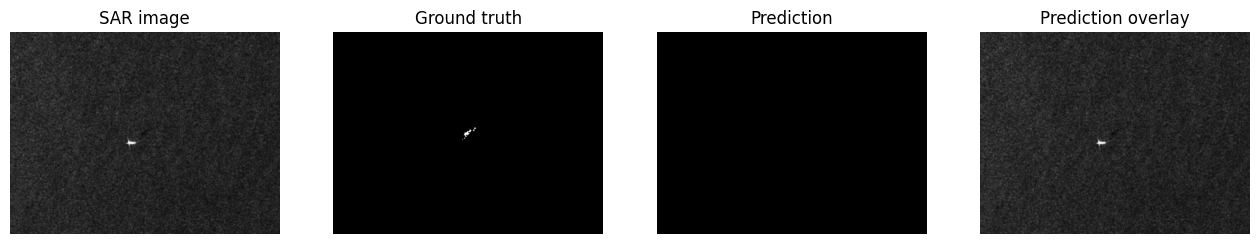

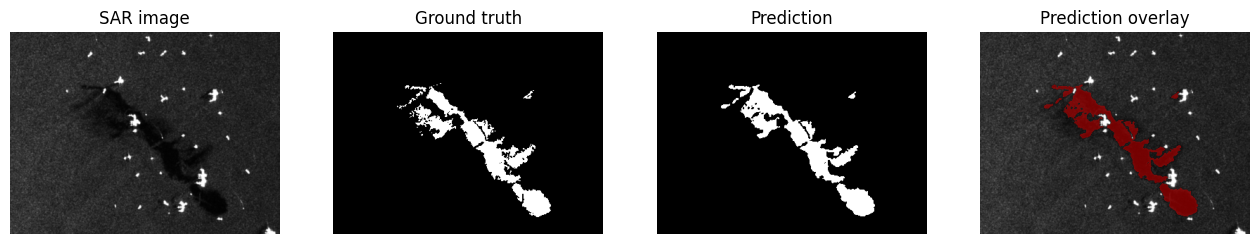

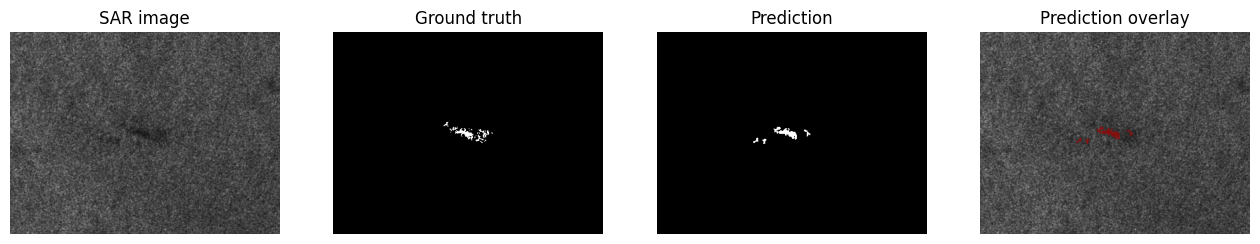

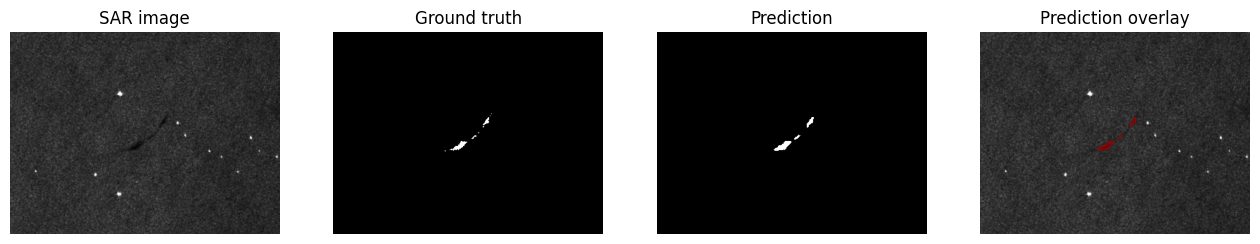

In [ ]:
show_test_prediction(0)
show_test_prediction(3)
show_test_prediction(7)
show_test_prediction(12)

In [ ]:
from google.colab import files

files.download(
    str(MODEL_PATH)
)

files.download(
    str(CONFIG_PATH)
)

files.download(
    str(TEST_METRICS_PATH)
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
sample_path = DATA_ROOT / test_df.iloc[0]["image_path"]

print(sample_path)

/content/oilspill-data/IMAGES/IMG-RGB/IMG_07_TILE_001.png
